# Business Feature Engineering and Five Component Selection

The broader compact WoE study constructed 31 representations from 20 original candidates and 11 engineered alternatives. Twenty-four had distinct, varying early-training WoE. The selected five-component main model required six raw fields. Its 2015 Q1 log loss was 0.466838 versus 0.466607 for the original scorecard.

This notebook reads packaged aggregate evidence. The complete research code is in ../research/business_feature_woe_selection_20261122/business_woe_selection.py. A full source rerun uses the business-woe stage after preparation and calibration dependencies.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

repo = Path.cwd()
if not (repo / "project_paths.py").exists():
    repo = repo.parent
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

folder = repo / "research/business_feature_woe_selection_20261122"
register = pd.read_csv(folder / "candidate_register.csv")
assert len(register) == 31
assert register.selection_status.eq("Eligible").sum() == 24
counts = register[["early_observed", "early_missing", "early_invalid", "early_unseen"]].sum(axis=1)
assert counts.eq(33257).all()
register.iloc[20:][["feature", "sources", "meaning", "selection_status"]]

feature,sources,meaning,selection_status
revolving_balance_income,"['revol_bal', 'annual_inc']",Revolving balance divided by annual reported income,Eligible
open_account_share,"['open_acc', 'total_acc']",Share of recorded credit lines currently open,Eligible
listed_loan_income,"['audit_loan_amnt', 'annual_inc']",Listed loan amount divided by annual reported income; underwriting revisions possible,Eligible
credit_history_months,"['earliest_cr_line', 'audit_issue_month']",Months from earliest credit line to origination; origination month proxies scoring month,Eligible
debt_adjusted_income,"['annual_inc', 'dti']",Reported gross income multiplied by one minus DTI; mortgage and requested loan absent from source DTI,Eligible
combined_burden,"['dti', 'revol_util']",DTI multiplied by revolving utilisation divided by 100,Eligible
inquiries_simple,['inq_last_6mths'],Four readable inquiry groups,Same early WoE as inq_last_6mths
utilisation_business,['revol_util'],"Zero, quarter-limit bands, and over-limit state",Eligible
delinquency_profile,"['delinq_2yrs', 'mths_since_last_delinq']",Cross-classification of recorded 2y count and last-delinquency recency; source event definitions retained,Eligible
purpose_detailed,['purpose'],Recorded purpose labels; categories below 100 fitting loans pooled,Eligible


## Screening

Five early-training WoE columns were constant and two were exact duplicate encodings. The primary pool contains 23 candidates. Listed loan-to-income is reserved for a 24-candidate conditional pool because its amount can reflect underwriting revisions. Credit history uses origination month as a scoring-month proxy. Application term is confirmed available at scoring.

In [2]:
register.loc[register.selection_status.ne("Eligible"), ["feature", "selection_status"]]

feature,selection_status
pub_rec,Same early WoE as mths_since_last_record
collections_12_mths_ex_med,Constant early-training WoE
acc_now_delinq,Constant early-training WoE
chargeoff_within_12_mths,Constant early-training WoE
delinq_amnt,Constant early-training WoE
tax_liens,Constant early-training WoE
inquiries_simple,Same early WoE as inq_last_6mths


## Temporal selection

Fitting uses 2010–2011, forward additions use 2012 H1 loss and path size uses 2012 H2. The smallest path within one paired standard error of the best H2 loss is retained, with at most five components. The selected models are refitted on all 2010–2012 training loans.

In [3]:
paths = pd.read_csv(folder / "selection_path.csv")
paths[["pool", "step", "added", "rank_log_loss", "confirm_log_loss", "selected_size"]]

pool,step,added,rank_log_loss,confirm_log_loss,selected_size
Selected business WoE,1,revol_util,0.439420,0.431101,False
Selected business WoE,2,debt_adjusted_income,0.435830,0.426313,False
Selected business WoE,3,inq_last_6mths,0.432393,0.423804,False
Selected business WoE,4,purpose,0.429991,0.422260,False
Selected business WoE,5,mths_since_last_delinq,0.429571,0.421985,True
Selection with listed-amount ratio,1,listed_loan_income,0.438801,0.428905,False
Selection with listed-amount ratio,2,revol_util,0.433940,0.426749,False
Selection with listed-amount ratio,3,inq_last_6mths,0.430203,0.424344,False
Selection with listed-amount ratio,4,purpose,0.428323,0.422799,False
Selection with listed-amount ratio,5,debt_adjusted_income,0.426761,0.420188,True


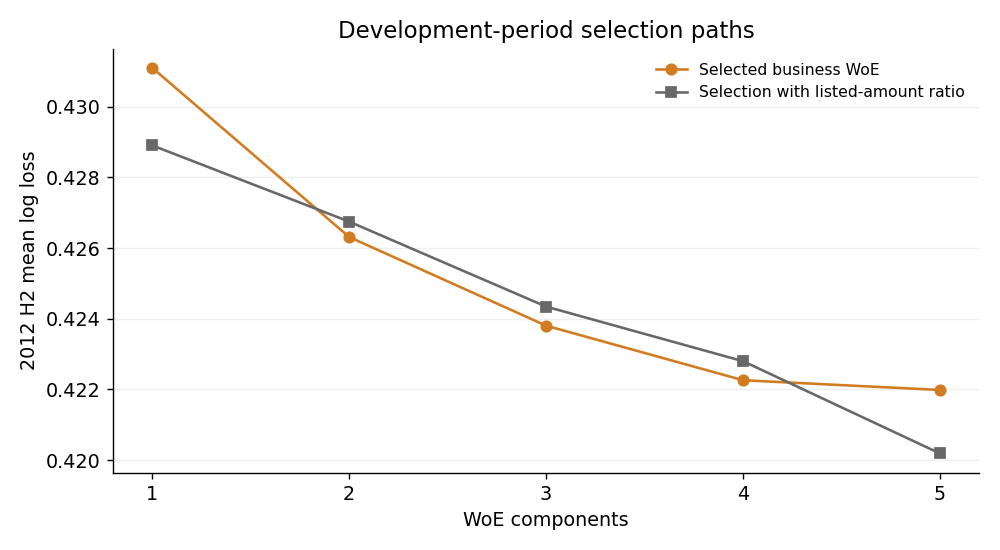

In [4]:
figure, axis = plt.subplots(figsize=(8, 4.4))
for (label, group), colour, marker in zip(
    paths.groupby("pool", sort=False), ["#D17C21", "#686868"], ["o", "s"]
):
    axis.plot(group.step, group.confirm_log_loss, label=label, marker=marker, color=colour)
axis.set(xlabel="WoE components", ylabel="2012 H2 mean log loss", xticks=[1, 2, 3, 4, 5],
         title="Development-period selection paths")
axis.legend(frameon=False, fontsize=9)
axis.grid(axis="y", alpha=.2)
figure.tight_layout()
plt.show()

## Selected components

The income proxy combines annual income and DTI. Missing delinquency recency retains its own bin and recorded source meaning. Term is an additional calibration input.

In [5]:
specification = json.loads((folder / "compact_business_scorecards.json").read_text())
chosen = specification["models"]["Selected business WoE"]
assert len(chosen["selected_features"]) == 5 and len(chosen["raw_inputs"]) == 6
coefficients = pd.read_csv(folder / "model_coefficients.csv")
assert not coefficients.positive_direction_flag.any()
coefficients

model,feature,coefficient,positive_direction_flag
Selected business WoE,revol_util,-1.071097,False
Selected business WoE,debt_adjusted_income,-1.101012,False
Selected business WoE,inq_last_6mths,-1.151774,False
Selected business WoE,purpose,-0.995658,False
Selected business WoE,mths_since_last_delinq,-1.152743,False
Selection with listed-amount ratio,listed_loan_income,-0.815511,False
Selection with listed-amount ratio,revol_util,-1.025814,False
Selection with listed-amount ratio,inq_last_6mths,-1.210642,False
Selection with listed-amount ratio,purpose,-0.900945,False
Selection with listed-amount ratio,debt_adjusted_income,-0.665736,False


## Common later-period comparison

All seven rows use the same 84,175 labelled loans and term offsets fitted separately for each model on 2014 outcomes. Lower log loss and higher AUC are preferred.

In [6]:
comparison = pd.read_csv(repo / "results/all_models_2015Q1.csv")
assert len(comparison) == 7 and comparison.loans.eq(84175).all() and comparison.bad.eq(15978).all()
comparison[["model", "input_representation", "raw_fields", "log_loss", "auc"]]

model,input_representation,raw_fields,log_loss,auc
Five-variable WoE,5 WoE components,5,0.466607,0.644918
Five-field engineered WoE,5 WoE components,5,0.466453,0.645205
Selected business WoE,5 WoE components,6,0.466838,0.643994
WoE with listed-amount ratio,5 WoE components,6,0.468265,0.642131
Engineered main effects,"41 locked columns, 37 nonzero",14,0.463457,0.654905
Pattern based full ridge,42 encoded columns,15,0.463339,0.655618
Pattern based RF selection,22 encoded columns,5,0.468003,0.640866


## Decision

The selected business WoE and conditional amount-ratio models have higher later-period loss. The original five-variable WoE remains the primary model. Candidate coverage, paths, coefficients, bins, points, paired comparisons and the original numerical-check record accompany the research code. The compact alternatives provide further development comparisons using previously studied outcome cohorts.